
# XGBoost (Extreme Gradient Boosting)

XGBoost, which stands for Extreme Gradient Boosting, is an optimized and scalable implementation of the gradient boosting algorithm.

It is an ensemble learning technique that builds multiple decision trees sequentially, where each new tree attempts to correct the errors made by the previous trees.

XGBoost improves upon traditional Gradient Boosting through regularization, efficient computation, parallel processing during tree construction, and several optimization techniques.

Unlike traditional Gradient Boosting, XGBoost incorporates additional mechanisms to control model complexity and reduce overfitting.

## How XGBoost Works

1. The model begins with an initial prediction.
2. It calculates the errors made by the current model.
3. A new decision tree is constructed to improve the predictions.
4. The new tree's contribution is controlled by the learning rate.
5. Regularization helps control model complexity.
6. The process continues until the specified number of boosting rounds is reached or another stopping condition is met.

## Types of XGBoost Models

### 1.XGBoost Regressor

Used to predict continuous numerical values.

Examples:
- House price prediction
- Sales forecasting
- Stock price estimation
- Demand prediction

### 2. XGBoost Classifier

Used to predict categorical outcomes.

Examples:
- Fraud detection
- Customer churn prediction
- Disease classification
- Credit risk assessment

## Important XGBoost Parameters

- `n_estimators`: Number of boosting rounds.
- `learning_rate`: Controls the contribution of each tree.
- `max_depth`: Maximum depth of each tree.
- `subsample`: Fraction of training observations used for each tree.
- `colsample_bytree`: Fraction of features sampled for each tree.
- `reg_alpha`: L1 regularization.
- `reg_lambda`: L2 regularization.
- `min_child_weight`: Minimum sum of instance weights required in a child node.

## Advantages

- High predictive performance.
- Supports both regression and classification.
- Includes regularization to control overfitting.
- Handles nonlinear relationships and feature interactions.
- Supports missing-value handling.
- Offers feature importance measurements.

## Limitations

- Requires careful hyperparameter tuning.
- Can overfit if model complexity is not controlled.
- May require substantial computational resources for large datasets.
- Less interpretable than simple linear models.

## Applications

XGBoost is widely used in finance, healthcare, marketing, fraud detection, forecasting, and many other predictive modelling tasks.

In [12]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
import xgboost as xgb
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score,roc_curve)

In [13]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.


## Regression

In [14]:
# Load California Housing dataset
housing = fetch_california_housing()

# Convert features into DataFrame
housing_df = pd.DataFrame(housing.data,columns=housing.feature_names)

# Add target variable
housing_df['MedHouseVal'] = housing.target

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [16]:
# Column names
print("\nColumns:")
print(housing_df.columns.tolist())

# Dataset information
print("\nDataset Information:")
housing_df.info()

# Statistical summary
print("\nStatistical Summary:")
display(housing_df.describe())

# Missing values
print("\nMissing Values:")
print(housing_df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", housing_df.duplicated().sum())

# Target variable summary
print("\nTarget Variable Summary:")
print("Mean:", housing_df['MedHouseVal'].mean())
print("Median:", housing_df['MedHouseVal'].median())
print("Minimum:", housing_df['MedHouseVal'].min())
print("Maximum:", housing_df['MedHouseVal'].max())


Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows: 0

Target Variable Summary:
Mean: 2.0685581690891475
Median: 1.797
Minimum: 0.14999
Maximum: 5.00001


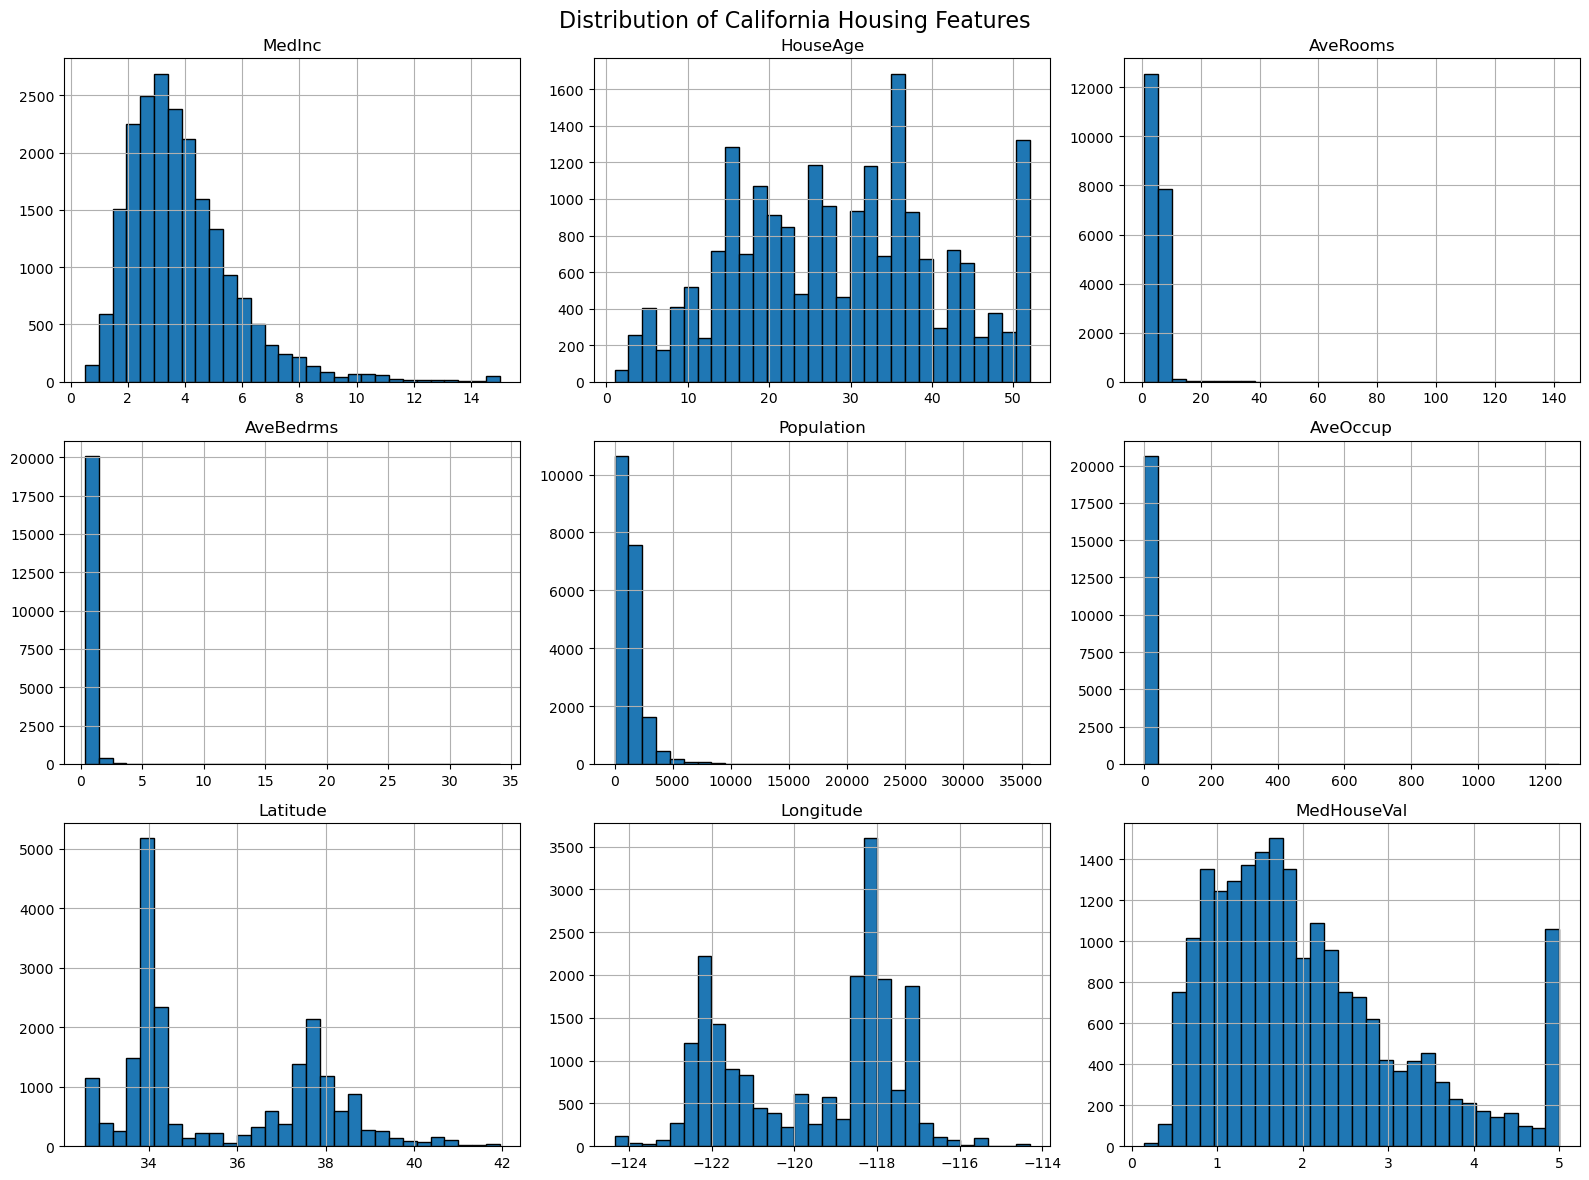

In [17]:
# numerical features distribution
# Plot feature distributions
housing_df.hist(figsize=(16, 12),bins=30,edgecolor='black')

plt.suptitle('Distribution of California Housing Features',fontsize=16)

plt.tight_layout()
plt.show()

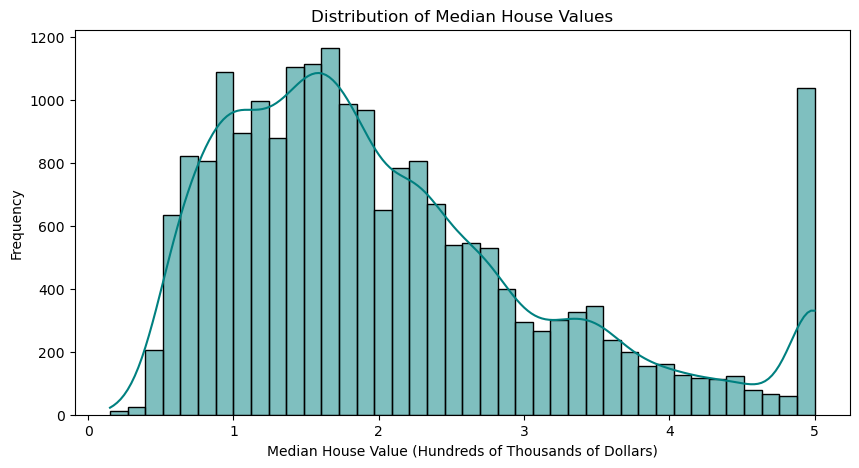

In [18]:
# Target variable distribution

plt.figure(figsize=(10, 5))

sns.histplot(data=housing_df,x='MedHouseVal',bins=40,kde=True,color='teal')

plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value (Hundreds of Thousands of Dollars)')
plt.ylabel('Frequency')

plt.show()

KeyError: 'Channel'

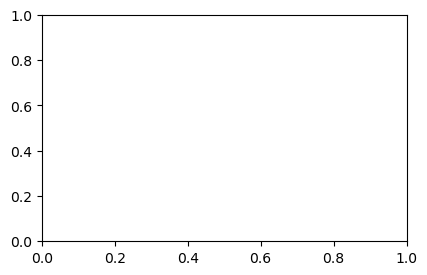

In [19]:
# outlier detection
plt.figure(figsize=(16, 10))

for i, column in enumerate(df.columns, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(y=housing_df[column],color='skyblue')

    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

In [ ]:
# feature rlship with target cvariable

## Classification

### Wholesale customers

In [2]:
# load dataset
df = pd.read_csv('../Datasets/Wholesale customers data.csv')

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [4]:
# Preprocessing
X = df.drop('Channel', axis=1)
y = df['Channel'].map({1:1, 2:0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [5]:
# Modelling
params = {
    'objective':'binary:logistic',
    'max_depth':4,
    'learning_rate':0.1,
    'n_estimators':100,
    'alpha':10
}

model = XGBClassifier(**params)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [6]:
# Evaluation
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy)

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9090909090909091

Classification Report
              precision    recall  f1-score   support

           0       0.80      0.92      0.85        38
           1       0.97      0.90      0.93        94

    accuracy                           0.91       132
   macro avg       0.88      0.91      0.89       132
weighted avg       0.92      0.91      0.91       132



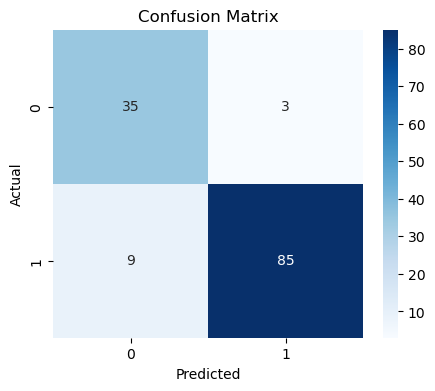

In [7]:
# confusion matrix
plt.figure(figsize=(5,4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<Figure size 800x600 with 0 Axes>

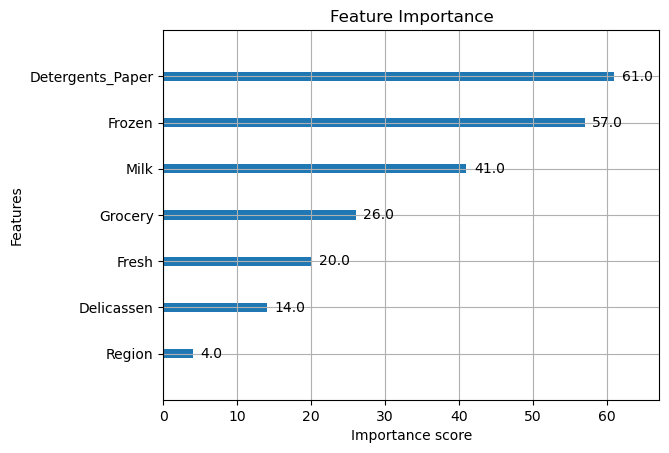

In [10]:
# feature importance
import xgboost as xgb
from xgboost import XGBClassifier
plt.figure(figsize=(8,6))
xgb.plot_importance(model)
plt.title("Feature Importance")
plt.show()

ImportError: You must install graphviz to plot tree

<Figure size 2000x1000 with 0 Axes>

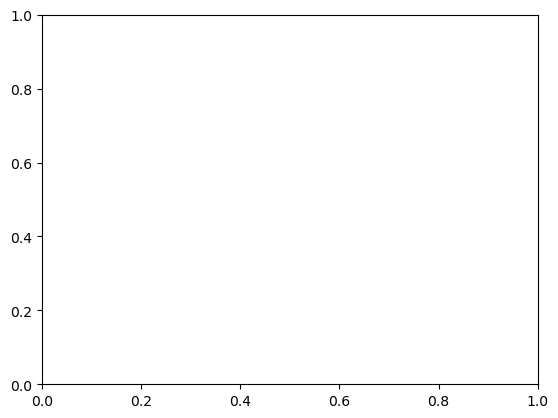

In [11]:
# xgboost decision tree
plt.figure(figsize=(20,10))
xgb.plot_tree(model, num_trees=0)
plt.show()